<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_2_hidden_layer_sequential_jax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PINN solution to the pendulum equation in the [0,50sec] range using sequential PINNs at 10 secs intervals.

 Starting Sequential PINN (Domain Decomposition)  

--- Training Interval 1/5 [0.0s to 10.0s] ---
Initial Conditions -> Theta: 0.7854, Velocity: 0.0000


/tmp/ipykernel_4315/1843740746.py:124: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Chunk Solved! Final Loss: 0.000008

--- Training Interval 2/5 [10.0s to 20.0s] ---
Initial Conditions -> Theta: -0.7706, Velocity: 0.1404
Chunk Solved! Final Loss: 0.000011

--- Training Interval 3/5 [20.0s to 30.0s] ---
Initial Conditions -> Theta: 0.7285, Velocity: -0.2769
Chunk Solved! Final Loss: 0.000004

--- Training Interval 4/5 [30.0s to 40.0s] ---
Initial Conditions -> Theta: -0.6603, Velocity: 0.4047
Chunk Solved! Final Loss: 0.000004

--- Training Interval 5/5 [40.0s to 50.0s] ---
Initial Conditions -> Theta: 0.5692, Velocity: -0.5203
Chunk Solved! Final Loss: 0.000003

All 5 intervals completed in 31.43 seconds!


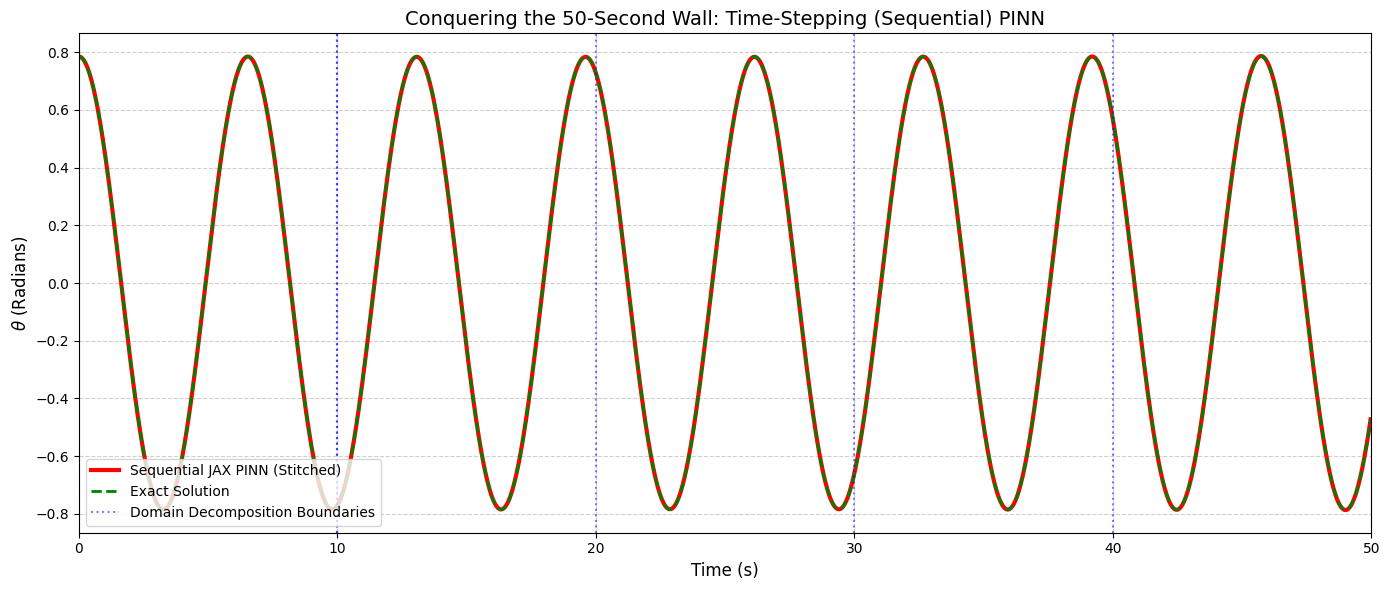

In [2]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad, grad, vmap

# Force JAX to use 64-bit precision
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp
import time

# ==========================================
# 2-Layer PINN Architecture (Position Only)
# ==========================================
def unpack_weights(params, H):
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1)
    return W1, b1, W2, b2, W3, b3

def pack_weights(W1, b1, W2, b2, W3, b3):
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten()
    ])

def predict_theta(params, t_scalar, H):
    W1, b1, W2, b2, W3, b3 = unpack_weights(params, H)

    # We solve in 10-second chunks, so we scale locally!
    t_chunk_max = 10.0
    tau = t_scalar / t_chunk_max

    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)
    theta = jnp.dot(a2, W3) + b3
    return theta[0, 0]

# ==========================================
# Universal AutoDiff Physics Builder
# ==========================================
# 1. Ask JAX to build the derivatives
predict_velocity = grad(predict_theta, argnums=1)
predict_acceleration = grad(predict_velocity, argnums=1)

# 2. Vectorize the scalar functions
vmap_theta = vmap(predict_theta, in_axes=(None, 0, None))
vmap_velocity = vmap(predict_velocity, in_axes=(None, 0, None))
vmap_acceleration = vmap(predict_acceleration, in_axes=(None, 0, None))

def compute_loss(params, t_domain, t_ic, theta_0, omega_0, H):
    t_flat = t_domain.flatten()
    t_ic_flat = t_ic.flatten()

    # Physics Loss (AutoDiff)
    theta = vmap_theta(params, t_flat, H)
    acceleration = vmap_acceleration(params, t_flat, H)
    residual = acceleration + jnp.sin(theta)
    loss_ode = jnp.mean(residual**2)

    # Initial Condition Loss (AutoDiff)
    theta_pred_ic = vmap_theta(params, t_ic_flat, H)
    velocity_pred_ic = vmap_velocity(params, t_ic_flat, H)
    loss_ic_position = jnp.mean((theta_pred_ic - theta_0)**2)
    loss_ic_velocity = jnp.mean((velocity_pred_ic - omega_0)**2)

    return loss_ode + loss_ic_position + loss_ic_velocity

loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

def scipy_objective(params, t_domain, t_ic, theta_0, omega_0, H):
    loss, grads = loss_and_grad(params, t_domain, t_ic, theta_0, omega_0, H)
    return float(loss), np.array(grads)

# ==========================================
# Sequential Training Setup
# ==========================================
H = 32
t_chunk = 10.0 # Solve 10 seconds at a time
intervals = 5  # 5 intervals * 10 seconds = 50 seconds total

# The local time domain is ALWAYS [0, 10] for the neural network
t_domain_local = jnp.linspace(0, t_chunk, 400).reshape(-1, 1)
t_ic = jnp.array([[0.0]])

# Global Initial Conditions at t = 0
global_theta_0 = np.pi / 4
current_theta_0 = global_theta_0
current_omega_0 = 0.0

np.random.seed(42)
W1 = np.random.randn(1, H) * 10.0 # 10.0 is plenty for a 10-second chunk
b1 = np.zeros((1, H))
W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = np.zeros((1, 1))
current_weights = pack_weights(W1, b1, W2, b2, W3, b3)

# Lists to store the stitched results
stitched_t = []
stitched_theta = []

print("==================================================")
print(" Starting Sequential PINN (Domain Decomposition)  ")
print("==================================================")

start_total_time = time.time()

for step in range(intervals):
    t_start = step * t_chunk
    t_end = (step + 1) * t_chunk
    print(f"\n--- Training Interval {step + 1}/{intervals} [{t_start}s to {t_end}s] ---")
    print(f"Initial Conditions -> Theta: {float(current_theta_0):.4f}, Velocity: {float(current_omega_0):.4f}")

    # Train the network on the current 10-second window
    res = minimize(
        fun=scipy_objective,
        x0=current_weights,
        args=(t_domain_local, t_ic, current_theta_0, current_omega_0, H),
        method='L-BFGS-B',
        jac=True,
        options={'maxiter': 5000, 'maxfun': 50000, 'disp': False}
    )

    current_weights = res.x
    print(f"Chunk Solved! Final Loss: {res.fun:.6f}")

    # Evaluate the predictions over this chunk
    t_plot_local = np.array(t_domain_local).flatten()
    theta_pred_local = np.array(vmap_theta(current_weights, t_plot_local, H))

    # Shift the local time to global time for plotting
    global_time_segment = t_plot_local + t_start

    # Save the results to our stitched lists
    # (We drop the last point to avoid overlapping duplicates when stitching)
    stitched_t.extend(global_time_segment[:-1])
    stitched_theta.extend(theta_pred_local[:-1])

    # The Magic Step: Use the exact end-state of this network
    # as the Initial Conditions for the next network!
    t_final_local = jnp.array([t_chunk])
    current_theta_0 = vmap_theta(current_weights, t_final_local, H)[0]
    current_omega_0 = vmap_velocity(current_weights, t_final_local, H)[0]

elapsed = time.time() - start_total_time
print(f"\nAll 5 intervals completed in {elapsed:.2f} seconds!")

# ==========================================
# Evaluation and Plotting
# ==========================================
stitched_t = np.array(stitched_t)
stitched_theta = np.array(stitched_theta)

# Calculate Exact Solution for the full 50 seconds
k = np.sin(global_theta_0 / 2)
m = k**2
sn, cn, dn, ph = sp.ellipj(stitched_t, m)
exact_solution = 2 * np.arcsin(k * (cn / dn))

plt.figure(figsize=(14, 6))

# Plot the stitched PINN
plt.plot(stitched_t, stitched_theta, 'r-', linewidth=3, label='Sequential JAX PINN (Stitched)')
plt.plot(stitched_t, exact_solution, 'g--', linewidth=2, label='Exact Solution')

# Draw vertical lines to show where the domain was sliced
for step in range(1, intervals):
    plt.axvline(x=step * t_chunk, color='blue', linestyle=':', alpha=0.5)
plt.axvline(x=t_chunk, color='blue', linestyle=':', alpha=0.5, label='Domain Decomposition Boundaries')

plt.title("Conquering the 50-Second Wall: Time-Stepping (Sequential) PINN", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("$\\theta$ (Radians)", fontsize=12)
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(0, 50)
plt.tight_layout()
plt.show()